# SuraApp — Model Training (EfficientNetB0)
**Light Pollution Classification — Bortle Scale**

| Label | Bortle | Class ID |
|-------|--------|----------|
| High | 7–9 | 0 |
| Low | 1–3 | 1 |
| Moderate | 4–6 | 2 |

**Dataset distribution:** High: 200 | Low: 273 | Moderate: 284 | Total: 757

**Before starting:** Make sure SuraApp_Dataset is in Google Drive:
```
MyDrive/SuraApp_Dataset/
├── High/
├── Low/
└── Moderate/
```

## Cell 1 — Mount Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')
print('✅ Drive mounted')

Mounted at /content/drive
✅ Drive mounted


## Cell 2 — Settings & Dataset Check

In [4]:
from pathlib import Path

DATASET_PATH = Path('/content/drive/MyDrive/SuraApp_Dataset')
MODEL_SAVE   = Path('/content/drive/MyDrive/sura_mobilenet.h5')
TFLITE_SAVE  = Path('/content/drive/MyDrive/sura_model.tflite')

IMG_SIZE   = 224
BATCH_SIZE = 32
EPOCHS_P1  = 20   # Phase 1: head only
EPOCHS_P2  = 10   # Phase 2: fine-tune
LABELS     = ['High', 'Low', 'Moderate']

# Verify dataset folders exist and count images
print('📂 Dataset check:')
total = 0
for label in LABELS:
    folder = DATASET_PATH / label
    if not folder.exists():
        print(f'  ❌ {label}: folder NOT FOUND at {folder}')
    else:
        count = len([f for f in folder.glob('*') if f.suffix.lower() in ['.jpg', '.jpeg', '.png', '.webp', '.bmp', '.tiff', '.gif']])
        print(f'  ✅ {label}: {count} images')
        total += count
print(f'  📊 Total: {total} images')

📂 Dataset check:
  ✅ High: 200 images
  ✅ Low: 273 images
  ✅ Moderate: 284 images
  📊 Total: 757 images


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 61.6 MB/s eta 0:00:00
🔄 Converting images...
  ✓ IMG_6449.HEIC
  ✓ IMG_6446.HEIC
  ✓ IMG_6445.HEIC

✅ Converted: 3 | Failed: 0


## Cell 3 — Load & Split Dataset (Train 606 / Validation 64 / Test 87)

In [5]:
import tensorflow as tf
import numpy as np

train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    labels='inferred',
    label_mode='categorical',
    class_names=LABELS,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    validation_split=0.20,
    subset='training',
    seed=123
)

remaining_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    labels='inferred',
    label_mode='categorical',
    class_names=LABELS,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    validation_split=0.20,
    subset='validation',
    seed=123
)

remaining_size = len(remaining_ds)
val_size       = remaining_size // 2

val_ds_raw  = remaining_ds.take(val_size)
test_ds_raw = remaining_ds.skip(val_size)

print('Class names :', train_ds_raw.class_names)
print(f'Train batches: {len(train_ds_raw)}')
print(f'Val batches  : {len(val_ds_raw)}')
print(f'Test batches : {len(test_ds_raw)}')

Found 757 files belonging to 3 classes.
Using 606 files for training.
Found 757 files belonging to 3 classes.
Using 151 files for validation.
Class names : ['High', 'Low', 'Moderate']
Train batches: 19
Val batches  : 2
Test batches : 3


## Cell 4 — Preprocessing & Augmentation
> `.cache()` is applied **after normalization** and **before augmentation** so each epoch sees freshly augmented images.

In [6]:
import tensorflow as tf

efficientnet_preprocess = tf.keras.applications.efficientnet.preprocess_input

AUTOTUNE = tf.data.AUTOTUNE

augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomBrightness(0.1),
    tf.keras.layers.RandomContrast(0.1),
], name='augmentation')

def prepare_train(ds):
    return (
        ds
        .map(lambda x, y: (efficientnet_preprocess(x), y), num_parallel_calls=AUTOTUNE)
        .cache()
        .map(lambda x, y: (augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
        .shuffle(500)
        .prefetch(AUTOTUNE)
    )

def prepare_eval(ds):
    return (
        ds
        .map(lambda x, y: (efficientnet_preprocess(x), y), num_parallel_calls=AUTOTUNE)
        .cache()
        .prefetch(AUTOTUNE)
    )

train_ds = prepare_train(train_ds_raw)
val_ds   = prepare_eval(val_ds_raw)
test_ds  = prepare_eval(test_ds_raw)

print('✅ Preprocessing ready')

✅ Preprocessing ready


## Cell 5 — Class Weights (handle imbalance)

In [7]:
# Count images per class from disk
counts = {}
for label in LABELS:
    counts[label] = len([f for f in (DATASET_PATH / label).glob('*')
                         if f.suffix.lower() in ['.jpg', '.jpeg', '.png', '.webp', '.bmp', '.tiff', '.gif']])

total = sum(counts.values())
n_cls = len(LABELS)

# Inverse-frequency weights — LABELS order matches class IDs (High=0, Low=1, Moderate=2)
class_weights = {i: total / (n_cls * counts[label]) for i, label in enumerate(LABELS)}

print('📊 Class weights:')
for i, label in enumerate(LABELS):
    print(f'  {label} (class {i}): {class_weights[i]:.3f}  [{counts[label]} images]')

📊 Class weights:
  High (class 0): 1.262  [200 images]
  Low (class 1): 0.924  [273 images]
  Moderate (class 2): 0.888  [284 images]


## Cell 6 — Build EfficientNetB0 Model

In [8]:
import tensorflow as tf
import numpy as np

# EfficientNetB0
base_model = tf.keras.applications.EfficientNetB0(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

inputs  = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x       = base_model(inputs, training=False)
x       = tf.keras.layers.GlobalAveragePooling2D()(x)
x       = tf.keras.layers.BatchNormalization()(x)
x       = tf.keras.layers.Dropout(0.4)(x)
outputs = tf.keras.layers.Dense(3, activation='softmax')(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print('✅ EfficientNetB0 ready')
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ EfficientNetB0 ready


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,534 (15.48 MB)

 Trainable params: 6,403 (25.01 KB)

 Non-trainable params: 4,052,131 (15.46 MB)

## Cell 7 — Phase 1: Train Head Only

In [9]:
callbacks_p1 = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy', patience=5, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=3, verbose=1
    )
]

print('🚀 Phase 1: Training head only...')
history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_P1,
    class_weight=class_weights,
    callbacks=callbacks_p1
)

best_p1 = max(history1.history['val_accuracy'])
print(f'\n✅ Phase 1 best val accuracy: {best_p1:.2%}')

🚀 Phase 1: Training head only...
Epoch 1/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 174s 2s/step - accuracy: 0.5660 - loss: 1.1679 - val_accuracy: 0.7969 - val_loss: 0.7356 - learning_rate: 0.0010
Epoch 2/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 42s 42ms/step - accuracy: 0.7409 - loss: 0.6302 - val_accuracy: 0.7812 - val_loss: 0.5999 - learning_rate: 0.0010
Epoch 3/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.7838 - loss: 0.5140 - val_accuracy: 0.8281 - val_loss: 0.5564 - learning_rate: 0.0010
Epoch 4/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 42ms/step - accuracy: 0.8234 - loss: 0.4348 - val_accuracy: 0.8281 - val_loss: 0.5119 - learning_rate: 0.0010
Epoch 5/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.8185 - loss: 0.4234 - val_accuracy: 0.8281 - val_loss: 0.4832 - learning_rate: 0.0010
Epoch 6/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.8416 - loss: 0.3576 - val_accuracy: 0.8281 - val_loss: 0.4613 - learning_rate: 0.0010
Epoch 7/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accurac

## Cell 9 — Training Curves

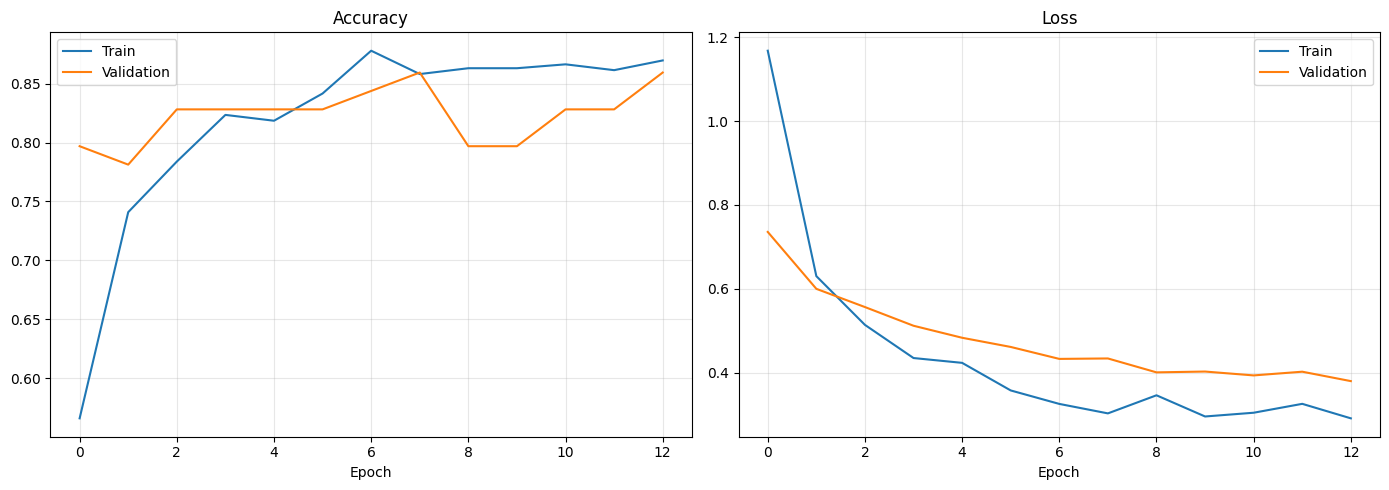

📈 Training curves saved


In [10]:
import matplotlib.pyplot as plt

acc      = history1.history['accuracy']
val_acc  = history1.history['val_accuracy']
loss     = history1.history['loss']
val_loss = history1.history['val_loss']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, train_v, val_v, title in [
    (axes[0], acc,  val_acc, 'Accuracy'),
    (axes[1], loss, val_loss, 'Loss')
]:
    ax.plot(train_v, label='Train')
    ax.plot(val_v,   label='Validation')
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/training_curves.png', dpi=150)
plt.show()
print('📈 Training curves saved')

## Cell 10 — Evaluate on Test Set & Confusion Matrix

🎯 Test Accuracy : 90.80%
   Test Loss     : 0.3562


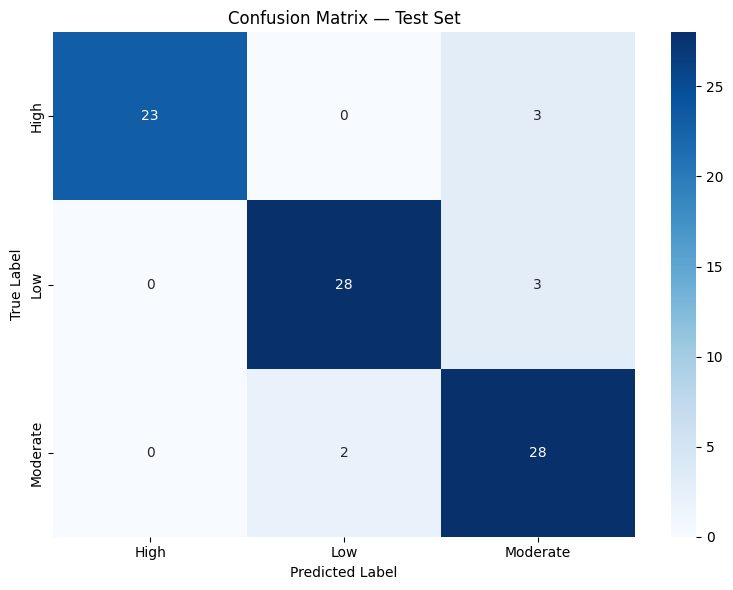


📋 Classification Report:
              precision    recall  f1-score   support

        High       1.00      0.88      0.94        26
         Low       0.93      0.90      0.92        31
    Moderate       0.82      0.93      0.88        30

    accuracy                           0.91        87
   macro avg       0.92      0.91      0.91        87
weighted avg       0.92      0.91      0.91        87



In [11]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# ── Evaluate on held-out TEST set (never seen during training) ────────────────
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f'🎯 Test Accuracy : {test_acc:.2%}')
print(f'   Test Loss     : {test_loss:.4f}')

# ── Predictions ──────────────────────────────────────────────────────────────
y_true, y_pred = [], []
for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

# ── Confusion Matrix ─────────────────────────────────────────────────────────
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt='d',
    xticklabels=LABELS, yticklabels=LABELS,
    cmap='Blues'
)
plt.title('Confusion Matrix — Test Set')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/confusion_matrix.png', dpi=150)
plt.show()

# ── Classification Report ────────────────────────────────────────────────────
print('\n📋 Classification Report:')
print(classification_report(y_true, y_pred, target_names=LABELS))

## Cell 11 — Confidence Threshold Check (60%)
> Images where the model is less than 60% confident will be **rejected** in SuraApp

In [ ]:
CONFIDENCE_THRESHOLD = 0.60

all_probs  = []
all_true   = []

for images, labels in test_ds:
    probs = model.predict(images, verbose=0)
    all_probs.extend(np.max(probs, axis=1))   # max confidence per image
    all_true.extend(np.argmax(labels.numpy(), axis=1))

all_probs = np.array(all_probs)
accepted  = all_probs >= CONFIDENCE_THRESHOLD

print(f'Confidence threshold : {CONFIDENCE_THRESHOLD:.0%}')
print(f'Accepted images      : {accepted.sum()} / {len(all_probs)}  ({accepted.mean():.1%})')
print(f'Rejected (low conf)  : {(~accepted).sum()} ({(~accepted).mean():.1%})')

Confidence threshold : 60%
Accepted images      : 69 / 87  (79.3%)
Rejected (low conf)  : 18 (20.7%)


## Cell 12 — Save Model & Export TFLite

In [12]:
# Save Keras model (.h5)
model.save(str(MODEL_SAVE))
print(f'💾 Keras model saved : {MODEL_SAVE}')

# Convert and quantize to TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]   # dynamic range quantization
tflite_model = converter.convert()

with open(TFLITE_SAVE, 'wb') as f:
    f.write(tflite_model)

size_mb = len(tflite_model) / 1024 / 1024
print(f'📦 TFLite model saved: {TFLITE_SAVE}')
print(f'   Size              : {size_mb:.2f} MB')
print('\n✅ Done! Next steps:')
print('  1. Copy sura_model.tflite → Flutter /assets/models/')
print('  2. Check which class has lowest recall in the report above')
print('  3. If any class < 75% recall → collect more images for that class')

💾 Keras model saved : /content/drive/MyDrive/sura_mobilenet.h5
Saved artifact at '/tmp/tmpk2lp9z9a'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_243')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  136019802145808: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  136019802148112: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  136020166317776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136020166317584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136020166318352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136020166319120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136020166314320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136020166317968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136020166318160: TensorSpec(shape=(), dtype=tf.resource, name=None)
 

In [ ]:
import numpy as np
from pathlib import Path
from PIL import Image
import tensorflow as tf
from google.colab import files

# ─── إعدادات ───────────────────────────────────────────────
MODEL_PATH = Path('/content/drive/MyDrive/sura_model.tflite')
IMG_SIZE   = 224
THRESHOLD  = 0.60
LABELS     = ['High', 'Low', 'Moderate']
LABELS_AR  = {
    'High':     'تلوث ضوئي عالٍ (Bortle 7-9)',
    'Low':      'تلوث ضوئي منخفض (Bortle 1-3)',
    'Moderate': 'تلوث ضوئي متوسط (Bortle 4-6)',
}

# ─── تحميل النموذج ─────────────────────────────────────────
interpreter = tf.lite.Interpreter(model_path=str(MODEL_PATH))
interpreter.allocate_tensors()
input_details  = interpreter.get_input_details()
output_details = interpreter.get_output_details()
print('✅ النموذج جاهز')

# ─── ارفعي صورك ────────────────────────────────────────────
uploaded = files.upload()

for filename, data in uploaded.items():
    # معالجة الصورة
    import io
    img = Image.open(io.BytesIO(data)).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
    arr = np.array(img, dtype=np.float32)
    arr = tf.keras.applications.efficientnet.preprocess_input(arr)
    arr = np.expand_dims(arr, axis=0)

    # التنبؤ
    interpreter.set_tensor(input_details[0]['index'], arr)
    interpreter.invoke()
    output = interpreter.get_tensor(output_details[0]['index'])[0]

    pred_idx   = np.argmax(output)
    confidence = float(output[pred_idx])
    label      = LABELS[pred_idx]
    accepted   = confidence >= THRESHOLD

    print(f'\n📸 {filename}')
    print(f'   التصنيف : {label} — {LABELS_AR[label]}')
    print(f'   الثقة   : {confidence:.1%}')
    print(f'   الحالة  : {"✅ مقبول" if accepted else "❌ مرفوض"}')
    print(f'   High={output[0]:.2%} | Low={output[1]:.2%} | Moderate={output[2]:.2%}')

✅ النموذج جاهز


Saving WhatsApp Image 2026-04-11 at 4.53.36 PM.jpeg to WhatsApp Image 2026-04-11 at 4.53.36 PM.jpeg

📸 WhatsApp Image 2026-04-11 at 4.53.36 PM.jpeg
   التصنيف : Moderate — تلوث ضوئي متوسط (Bortle 4-6)
   الثقة   : 91.1%
   الحالة  : ✅ مقبول
   High=6.02% | Low=2.88% | Moderate=91.11%
